# Stream A — NER Pipeline (Updated)

**Key change:** NewsCLIPpings metadata JSONs contain pre-extracted SpaCy entities
and caption text — no VisualNews / SpaCy re-run needed for NC pairs.

**Composite pair key:** `f"{id}_{int(falsified)}"` fixes the id-collision bug.

**Outputs:**
- `cache/ner/entities_newsclippings_{split}.pkl` — composite-keyed entity dicts
- `cache/ner/entities_verite.pkl`, `cache/ner/entities_mmfake.pkl` (unchanged)
- `cache/ner/entities_all.pkl` — merged
- `paper/tables/ner_entity_stats.csv`
- `paper/figures/ner_entity_distribution.png`, `ner_entity_ooc_vs_genuine.png`

## 1. Setup

In [1]:
import sys, pickle, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from tqdm import tqdm

sys.path.insert(0, str(Path('../../').resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style='whitegrid', font_scale=1.1)
C_OOC='#E05A4B'; C_GENUINE='#4B8AE0'

NER_CACHE    = CACHE / 'ner'
PAPER_FIGS   = ROOT  / 'paper' / 'figures'
PAPER_TABLES = ROOT  / 'paper' / 'tables'
for d in [NER_CACHE, PAPER_FIGS, PAPER_TABLES]: d.mkdir(parents=True, exist_ok=True)

METADATA_DIR = DATA / 'newsclippings' / 'metadata'

def savefig(name):
    p = PAPER_FIGS / f'{name}.png'
    plt.savefig(p, bbox_inches='tight', dpi=150)
    print(f'  Saved -> {p.relative_to(ROOT)}')

def savecsv(df, name):
    p = PAPER_TABLES / f'{name}.csv'
    df.to_csv(p, index=False)
    print(f'  Saved -> {p.relative_to(ROOT)}')

print(f'NER cache -> {NER_CACHE.relative_to(ROOT)}')
print(f'Metadata  -> {METADATA_DIR.relative_to(ROOT)}')

NER cache -> cache\ner
Metadata  -> data\newsclippings\metadata


## 2. Load SpaCy (for VERITE + MMFakeBench only)

In [2]:
SPACY_MODEL = None
for model_name in ['en_core_web_trf', 'en_core_web_sm']:
    try:
        nlp = spacy.load(model_name, disable=['tagger','parser','lemmatizer'])
        SPACY_MODEL = model_name
        print(f'  Loaded {model_name}')
        break
    except OSError:
        print(f'  {model_name} not found')

if SPACY_MODEL is None:
    raise RuntimeError('No SpaCy model. Run: python -m spacy download en_core_web_sm')

doc = nlp('Barack Obama visited Paris.')
print(f'  Smoke test: {[(e.text, e.label_) for e in doc.ents]}')

  en_core_web_trf not found
  Loaded en_core_web_sm
  Smoke test: [('Barack Obama', 'PERSON'), ('Paris', 'GPE')]


## 3. Load NC metadata — captions + pre-extracted entities

In [3]:
# metadata JSONs: list of dicts with id, caption, caption_entities_spacy, ...
ENTITY_TYPES_OF_INTEREST = {
    'PERSON','ORG','GPE','LOC','EVENT','FAC','PRODUCT','NORP','WORK_OF_ART'
}

metadata_by_id = {}  # str(image_id) -> {caption, entities_spacy, ...}
for split in ['train', 'val', 'test']:
    fpath = METADATA_DIR / f'{split}.json'
    if not fpath.exists():
        print(f'  WARNING: {fpath} not found')
        continue
    entries = load_json(fpath)
    if isinstance(entries, dict):
        entries = list(entries.values())
    for e in entries:
        metadata_by_id[str(e['id'])] = e

print(f'  Metadata loaded: {len(metadata_by_id):,} unique images')

# Quick sample
sample_key = next(iter(metadata_by_id))
s = metadata_by_id[sample_key]
print(f'  Sample id={sample_key}: caption[:80]={str(s.get("caption",""))[:80]}')
print(f'  Entities: {s.get("caption_entities_spacy", [])[:3]}')

  Metadata loaded: 466,748 unique images
  Sample id=728421: caption[:80]=Anthony Stokes last played a league game for Celtic in August
  Entities: [['Celtic', 'NORP'], ['Anthony Stokes', 'PERSON']]


## 4. Build NC entity caches from metadata

**Composite key:** `{id}_{int(falsified)}`

In [4]:
def build_nc_ner_cache(split, metadata_by_id, pairs):
    out_path = NER_CACHE / f'entities_newsclippings_{split}.pkl'
    if out_path.exists():
        ents = pickle.load(open(out_path,'rb'))
        # Check if it uses composite keys (new format)
        sample_key = next(iter(ents)) if ents else ''
        if '_' in sample_key:
            print(f'  NC/{split}: loaded from cache ({len(ents):,} entries, composite keys)')
            return ents
        print(f'  NC/{split}: old cache (no composite keys) -- rebuilding...')

    print(f'  Building NC/{split} NER from metadata ({len(pairs):,} pairs)...')
    ents = {}
    missing_meta = 0
    for row in pairs:
        pid      = str(row['id'])
        falsified = bool(row['falsified'])
        key      = f'{pid}_{int(falsified)}'
        meta     = metadata_by_id.get(pid)
        if meta is None:
            missing_meta += 1
            ents[key] = []
            continue
        # Use pre-extracted SpaCy entities from metadata
        raw_ents = meta.get('caption_entities_spacy', [])
        ents[key] = [
            {'text': e[0], 'label': e[1], 'start': -1, 'end': -1}
            for e in raw_ents
            if e[1] in ENTITY_TYPES_OF_INTEREST
        ]
    if missing_meta:
        print(f'    {missing_meta} pairs had no metadata entry')
    pickle.dump(ents, open(out_path,'wb'), protocol=4)
    n_with = sum(1 for v in ents.values() if v)
    print(f'  NC/{split}: {len(ents):,} entries | {n_with:,} with entities -> {out_path.name}')
    return ents

def load_newsclip(split):
    fpath = NEWSCLIP / f'{split}.json'
    raw = load_json(fpath)
    return raw.get('annotations', raw) if isinstance(raw, dict) else raw

nc_ner = {}
nc_pairs = {}
for split in ['train', 'val', 'test']:
    pairs = load_newsclip(split)
    nc_pairs[split] = pairs
    nc_ner[split] = build_nc_ner_cache(split, metadata_by_id, pairs)

nc_total = sum(len(v) for v in nc_ner.values())
nc_with_ents = sum(sum(1 for x in v.values() if x) for v in nc_ner.values())
print(f'\n  NC total: {nc_total:,} pairs | {nc_with_ents:,} with entities'
      f' ({nc_with_ents/nc_total*100:.1f}%)')

  Building NC/train NER from metadata (71,072 pairs)...
  NC/train: 71,072 entries | 71,068 with entities -> entities_newsclippings_train.pkl
  Building NC/val NER from metadata (7,024 pairs)...
  NC/val: 7,024 entries | 7,022 with entities -> entities_newsclippings_val.pkl
  Building NC/test NER from metadata (7,264 pairs)...
  NC/test: 7,264 entries | 7,264 with entities -> entities_newsclippings_test.pkl

  NC total: 85,360 pairs | 85,354 with entities (100.0%)


## 5. VERITE — NER (SpaCy)

In [5]:
VERITE_CSV = pd.read_csv(VERITE / 'VERITE.csv')
v_ids   = [f'verite_{i}' for i in range(len(VERITE_CSV))]
v_texts = VERITE_CSV['caption'].fillna('').tolist()

v_cache = NER_CACHE / 'entities_verite.pkl'
if v_cache.exists():
    verite_ner = pickle.load(open(v_cache,'rb'))
    print(f'  VERITE: loaded from cache ({len(verite_ner):,} entries)')
else:
    print(f'  Running SpaCy on VERITE ({len(v_texts):,} captions)...')
    verite_ner = {}
    BATCH = 256
    for i in tqdm(range(0, len(v_texts), BATCH), desc='NER VERITE'):
        b_ids = v_ids[i:i+BATCH]; b_texts = v_texts[i:i+BATCH]
        for pid, doc in zip(b_ids, nlp.pipe(b_texts, batch_size=BATCH)):
            verite_ner[pid] = [{'text':e.text,'label':e.label_,'start':e.start_char,'end':e.end_char}
                                for e in doc.ents if e.label_ in ENTITY_TYPES_OF_INTEREST]
    pickle.dump(verite_ner, open(v_cache,'wb'), protocol=4)
    print(f'  VERITE: {len(verite_ner):,} entries saved')

  VERITE: loaded from cache (1,001 entries)


## 6. MMFakeBench — NER (SpaCy)

In [6]:
raw = load_json(DATA / 'mmfakebench' / 'MMFakeBench_test.json')
mm_pairs = raw if isinstance(raw, list) else list(raw.values())
mm_ids   = [f'mmfake_{i}' for i in range(len(mm_pairs))]
mm_texts = [str(p.get('text','')).strip() for p in mm_pairs]

mm_cache = NER_CACHE / 'entities_mmfake.pkl'
if mm_cache.exists():
    mmfake_ner = pickle.load(open(mm_cache,'rb'))
    print(f'  MMFake: loaded from cache ({len(mmfake_ner):,} entries)')
else:
    print(f'  Running SpaCy on MMFake ({len(mm_texts):,} captions)...')
    mmfake_ner = {}
    BATCH = 256
    for i in tqdm(range(0, len(mm_texts), BATCH), desc='NER MMFake'):
        b_ids = mm_ids[i:i+BATCH]; b_texts = mm_texts[i:i+BATCH]
        for pid, doc in zip(b_ids, nlp.pipe([t or '' for t in b_texts], batch_size=BATCH)):
            mmfake_ner[pid] = [{'text':e.text,'label':e.label_,'start':e.start_char,'end':e.end_char}
                                for e in doc.ents if e.label_ in ENTITY_TYPES_OF_INTEREST]
    pickle.dump(mmfake_ner, open(mm_cache,'wb'), protocol=4)
    print(f'  MMFake: {len(mmfake_ner):,} entries saved')

  MMFake: loaded from cache (10,000 entries)


## 7. Merge and save

In [7]:
all_entities = {}
for split in ['train','val','test']:
    all_entities.update(nc_ner[split])
all_entities.update(verite_ner)
all_entities.update(mmfake_ner)

pickle.dump(all_entities, open(NER_CACHE/'entities_all.pkl','wb'), protocol=4)
print(f'  Merged: {len(all_entities):,} total entries')
print(f'    NC    : {sum(len(v) for v in nc_ner.values()):,}')
print(f'    VERITE: {len(verite_ner):,}')
print(f'    MMFake: {len(mmfake_ner):,}')

  Merged: 96,361 total entries
    NC    : 85,360
    VERITE: 1,001
    MMFake: 10,000


## 8. Entity stats and figures

In [8]:
# Compute stats across all datasets that have real entities
type_counter = Counter()
entity_per_pair = []
ooc_ent_counts, gen_ent_counts = [], []

# NC pairs with labels
for split in ['train','val','test']:
    for row in nc_pairs[split]:
        key = f'{row["id"]}_{int(row["falsified"])}'
        ents = nc_ner[split].get(key, [])
        n = len(ents)
        entity_per_pair.append(n)
        (ooc_ent_counts if row['falsified'] else gen_ent_counts).append(n)
        for e in ents: type_counter[e['label']] += 1

# VERITE + MMFake
for ner_dict in [verite_ner, mmfake_ner]:
    for pid, ents in ner_dict.items():
        entity_per_pair.append(len(ents))
        for e in ents: type_counter[e['label']] += 1

total_ents = sum(type_counter.values())
has_entity = sum(1 for v in all_entities.values() if v)
print(f'  Total entities  : {total_ents:,}')
print(f'  Pairs with >=1  : {has_entity:,} / {len(all_entities):,}'
      f' ({has_entity/len(all_entities)*100:.1f}%)')
print(f'  Avg/pair (NC)   : mean={np.mean(entity_per_pair[:len(nc_pairs["train"])+len(nc_pairs["val"])+len(nc_pairs["test"])]) if entity_per_pair else 0:.2f}')
print()
for etype, cnt in type_counter.most_common():
    print(f'  {etype:<20} {cnt:>8,}  ({cnt/max(total_ents,1)*100:.1f}%)')

stats_df = pd.DataFrame([(t,c,round(c/max(total_ents,1)*100,2)) for t,c in type_counter.most_common()],
                         columns=['entity_type','count','pct'])
savecsv(stats_df, 'ner_entity_stats')

  Total entities  : 256,617
  Pairs with >=1  : 93,118 / 96,361 (96.6%)
  Avg/pair (NC)   : mean=2.81

  PERSON                 98,369  (38.3%)
  GPE                    63,794  (24.9%)
  ORG                    52,021  (20.3%)
  NORP                   15,986  (6.2%)
  FAC                    11,403  (4.4%)
  LOC                     5,500  (2.1%)
  EVENT                   4,033  (1.6%)
  WORK_OF_ART             3,098  (1.2%)
  PRODUCT                 2,413  (0.9%)
  Saved -> paper\tables\ner_entity_stats.csv


  Saved -> paper\figures\ner_entity_distribution.png


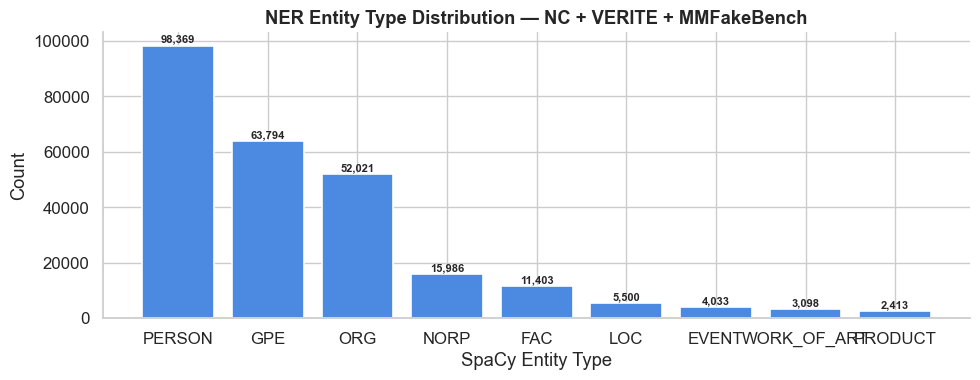

  Saved -> paper\figures\ner_entity_ooc_vs_genuine.png


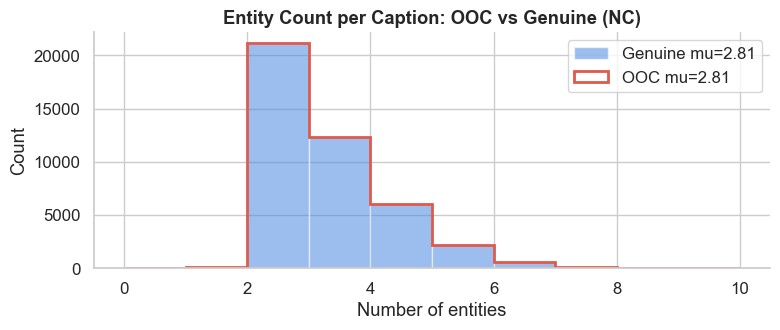

  Saved -> paper\tables\ner_entity_richness_ooc_vs_genuine.csv


In [9]:
# Entity type bar chart
labels = [t for t,_ in type_counter.most_common()]
counts = [c for _,c in type_counter.most_common()]

fig, ax = plt.subplots(figsize=(10,4))
bars = ax.bar(labels, counts, color='#4B8AE0', edgecolor='white', linewidth=1.2)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+total_ents*0.002,
            f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_title('NER Entity Type Distribution — NC + VERITE + MMFakeBench', fontweight='bold')
ax.set_ylabel('Count'); ax.set_xlabel('SpaCy Entity Type')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); savefig('ner_entity_distribution'); plt.show()

# OOC vs Genuine (NC only, since we now have real entities)
ooc_arr = np.array(ooc_ent_counts)
gen_arr = np.array(gen_ent_counts)
if len(ooc_arr) and len(gen_arr):
    fig, ax = plt.subplots(figsize=(8,3.5))
    max_bin = min(int(max(ooc_arr.max(),gen_arr.max()))+2, 20)
    bins = range(0, max_bin)
    ax.hist(gen_arr, bins=bins, alpha=0.55, color='#4B8AE0',
            label=f'Genuine mu={gen_arr.mean():.2f}')
    ax.hist(ooc_arr, bins=bins, histtype='step', linewidth=2.0, color='#E05A4B',
            label=f'OOC mu={ooc_arr.mean():.2f}')
    ax.set_title('Entity Count per Caption: OOC vs Genuine (NC)', fontweight='bold')
    ax.set_xlabel('Number of entities'); ax.set_ylabel('Count')
    ax.legend(); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout(); savefig('ner_entity_ooc_vs_genuine'); plt.show()

    richness_df = pd.DataFrame({'class':['genuine','ooc'],
        'mean':[round(gen_arr.mean(),4), round(ooc_arr.mean(),4)],
        'median':[float(np.median(gen_arr)), float(np.median(ooc_arr))],
        'n_pairs':[len(gen_arr), len(ooc_arr)]})
    savecsv(richness_df, 'ner_entity_richness_ooc_vs_genuine')

## 9. Done

In [10]:
print('='*55)
print('  NER pipeline complete (updated).')
print('='*55)
print()
print('  Cache files:')
for f in sorted(NER_CACHE.glob('*.pkl')):
    print(f'    {f.name:<40} {f.stat().st_size/1e6:.1f} MB')
print()
print(f'  SpaCy model : {SPACY_MODEL} (VERITE + MMFake only)')
print(f'  NC entities : from metadata pre-extraction (no SpaCy needed)')
print(f'  Key format  : {{id}}_{{int(falsified)}} (composite, fixes id-collision)')
print()
print('  ACTION REQUIRED: Delete old VG + entity_scorer NC caches before next step:')
print('    del cache/visual_grounding/vg_newsclippings_*.pkl')
print('    del cache/entity_scorer/features_newsclippings_*.pkl')
print('    del cache/entity_scorer/features_all.pkl')
print()
print('  Next: notebooks/02_stream_a/visual_grounding.ipynb')

  NER pipeline complete (updated).

  Cache files:
    entities_all.pkl                         11.4 MB
    entities_mmfake.pkl                      0.7 MB
    entities_newsclippings_test.pkl          0.9 MB
    entities_newsclippings_train.pkl         8.7 MB
    entities_newsclippings_val.pkl           0.8 MB
    entities_test.pkl                        0.0 MB
    entities_train.pkl                       0.4 MB
    entities_val.pkl                         0.0 MB
    entities_verite.pkl                      0.1 MB

  SpaCy model : en_core_web_sm (VERITE + MMFake only)
  NC entities : from metadata pre-extraction (no SpaCy needed)
  Key format  : {id}_{int(falsified)} (composite, fixes id-collision)

  ACTION REQUIRED: Delete old VG + entity_scorer NC caches before next step:
    del cache/visual_grounding/vg_newsclippings_*.pkl
    del cache/entity_scorer/features_newsclippings_*.pkl
    del cache/entity_scorer/features_all.pkl

  Next: notebooks/02_stream_a/visual_grounding.ipynb
